In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, MinMaxScaler

from tensorflow import keras
from tensorflow.keras import layers

In [22]:
df = pd.read_csv("penguins_size.csv")
df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [23]:
df=df.dropna()

In [24]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df["island"] = le.fit_transform(df["island"])
df["sex"] = le.fit_transform(df["sex"])
df["species"] = le.fit_transform(df["species"])

In [25]:
X = df.iloc[:,1:].values
y = df.iloc[:,0].values

In [26]:
le = LabelEncoder()
y = le.fit_transform(y)

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [28]:
scaler = MinMaxScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [29]:
n_classes = len(np.unique(y))

In [30]:
model = keras.Sequential([
    keras.Input(shape=(X_train.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(n_classes, activation="softmax")
])

In [31]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [32]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    validation_split=0.2
)

Epoch 1/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 63ms/step - accuracy: 0.2066 - loss: 1.1171 - val_accuracy: 0.2037 - val_loss: 1.0939
Epoch 2/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3568 - loss: 1.0673 - val_accuracy: 0.4444 - val_loss: 1.0521
Epoch 3/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6338 - loss: 1.0252 - val_accuracy: 0.7037 - val_loss: 1.0189
Epoch 4/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.8263 - loss: 0.9874 - val_accuracy: 0.7778 - val_loss: 0.9925
Epoch 5/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.7653 - loss: 0.9590 - val_accuracy: 0.7222 - val_loss: 0.9693
Epoch 6/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.7559 - loss: 0.9357 - val_accuracy: 0.7407 - val_loss: 0.9473
Epoch 7/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7465 - loss: 0.9109 - val_accuracy: 0.7407 - val_loss: 0.9265
Epoch 8/30
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.7465 - loss: 0.8884 - val_accuracy: 0.7407 - val_loss: 0.9052


In [33]:
loss, accuracy = model.evaluate(X_test, y_test)
print("Test Accuracy:", accuracy)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8955 - loss: 0.3877
Test Accuracy: 0.89552241563797


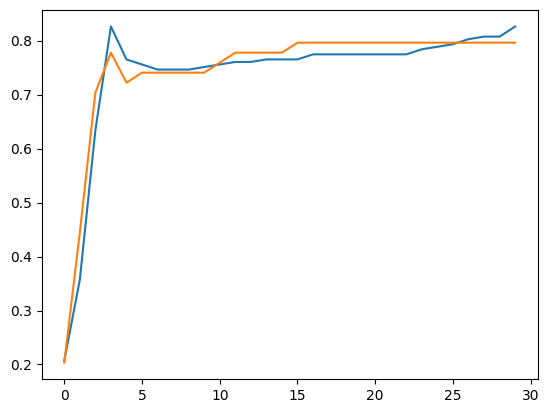

In [34]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")


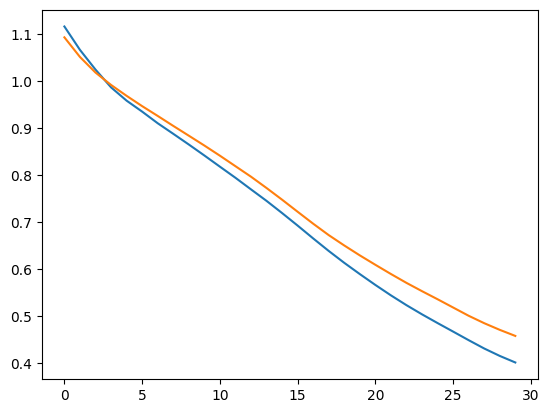

In [35]:
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
